In [64]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf

print(f"NumPy: {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"TensorFlow: {tf.__version__}")

NumPy: 2.1.3
Matplotlib: 3.10.0
TensorFlow: 2.21.0


In [65]:
from tensorflow.keras.layers import Dense
linear_layer = Dense(units= 1, activation="linear")

In [66]:
x = np.array([[200.0]])
print(x.shape)

prediction = linear_layer(x)
print("Prediction:",prediction)
print("weights: ", [w.shape for w in linear_layer.weights])
# print("Bias: ", [b.shape for b in linear_layer.bias])

(1, 1)
Prediction: tf.Tensor([[-257.91812]], shape=(1, 1), dtype=float32)
weights:  [TensorShape([1, 1]), TensorShape([1])]


In [67]:
x = np.array([[1],[2],[3],[1],[2],[3],[1],[2],[3],[9]])
print(x.shape)

(10, 1)


In [68]:
w = np.array([[1]])
print(w)
print(w.shape)

[[1]]
(1, 1)


In [69]:
print(x)

[[1]
 [2]
 [3]
 [1]
 [2]
 [3]
 [1]
 [2]
 [3]
 [9]]


In [70]:
W = np.array([[1, 2, 3]])
b = np.array([0, 0, 0])
print(W)
print(b)

[[1 2 3]]
[0 0 0]


In [71]:

Z = np.dot(x, W) + b
print(Z)
print(Z.shape)

[[ 1  2  3]
 [ 2  4  6]
 [ 3  6  9]
 [ 1  2  3]
 [ 2  4  6]
 [ 3  6  9]
 [ 1  2  3]
 [ 2  4  6]
 [ 3  6  9]
 [ 9 18 27]]
(10, 3)


In [72]:
x_train = np.array([[1.0], [2.0]])
y_train = np.array([[300.0], [500.0]])
print(x_train)
print(y_train)

print(x_train.shape)
print(y_train.shape)

[[1.]
 [2.]]
[[300.]
 [500.]]
(2, 1)
(2, 1)


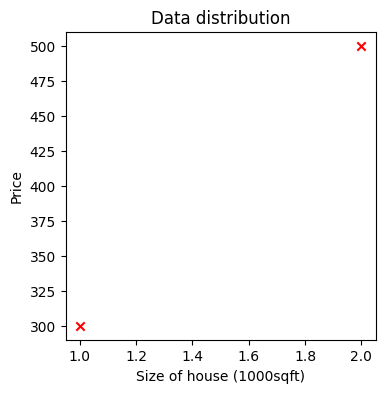

In [73]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.scatter(x_train, y_train, marker = 'x', c='r')
ax.set_xlabel("Size of house (1000sqft)")
ax.set_ylabel("Price")
ax.set_title("Data distribution")
plt.show()

In [74]:
linear_layer = tf.keras.layers.Dense(units = 1, activation='linear')

In [75]:
print(linear_layer.get_weights())

[]


In [76]:
a1 = linear_layer(x_train[0].reshape(1,1))
print(a1)

tf.Tensor([[-0.38706422]], shape=(1, 1), dtype=float32)


In [77]:
w, b = linear_layer.get_weights()
print(f"W: {w}")
print(f"b: {b}")

print(f"W shape: {w.shape}")
print(f"b shape: {b.shape}")

W: [[-0.38706422]]
b: [0.]
W shape: (1, 1)
b shape: (1,)


In [78]:

set_w = np.array([[200]])
set_b = np.array([100])

print(set_w.shape)
print(set_b.shape)

(1, 1)
(1,)


In [79]:
# assigning weights to the layer object

linear_layer.set_weights([set_w, set_b])

In [80]:
w, b = linear_layer.get_weights()

In [81]:
# prediction using tensorflow
pred_tf = linear_layer(x_train)
print(pred_tf)
print(pred_tf.shape)

tf.Tensor(
[[300.]
 [500.]], shape=(2, 1), dtype=float32)
(2, 1)


In [82]:
# prediction using numpy
# x: (10,1) , w:(1,3), b:(1,)

pred_np = np.dot(x_train,w) + b
print(pred_np)
print(pred_np.shape)

[[300.]
 [500.]]
(2, 1)


In [83]:
# calculate error

error = (y_train - pred_np) ** 2
print(error)

[[0.]
 [0.]]


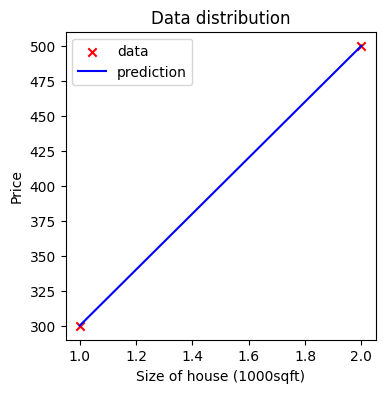

In [84]:
fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.scatter(x_train, y_train, marker = 'x', c='r', label = 'data')
ax.plot(x_train, pred_tf , c='b', label = 'prediction')
ax.set_xlabel("Size of house (1000sqft)")
ax.set_ylabel("Price")
ax.set_title("Data distribution")
plt.legend()
plt.show()

Logistic Regression

In [85]:
x = np.array([0,1,2,3,4,5], dtype=np.float32).reshape(-1,1)
y = np.array([0,0,0,1,1,1], dtype=np.int32).reshape(-1,1)
print(x)
print(y)
print(x.shape)
print(y.shape)

[[0.]
 [1.]
 [2.]
 [3.]
 [4.]
 [5.]]
[[0]
 [0]
 [0]
 [1]
 [1]
 [1]]
(6, 1)
(6, 1)


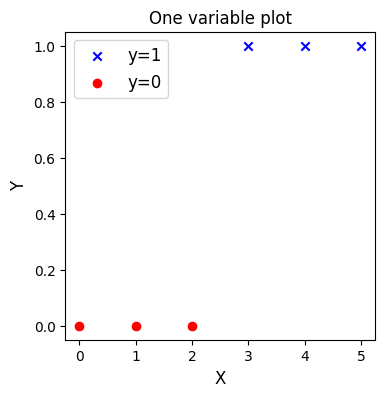

In [86]:
pos = (y==1)
neg = (y==0)

fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.scatter(x[pos], y[pos], label='y=1', marker='x', c='b')
ax.scatter(x[neg], y[neg], label='y=0', marker='o', c='r')
ax.set_xlabel("X", fontsize=12)
ax.set_ylabel("Y", fontsize=12)
ax.set_title("One variable plot")
ax.legend(fontsize= 12)
plt.show()

In [115]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(1,)),
    tf.keras.layers.Dense(units=1, activation='sigmoid', input_dim=1, name='L1')
    ]
    )
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [116]:
layer_1 = model.get_layer('L1')
print(layer_1)

<Dense name=L1, built=True>


In [117]:
w,b = model.get_weights()
print(f"w: {w}, w shape: {w.shape}")
print(f"b: {b}, b shape: {b.shape}")

w: [[0.50119364]], w shape: (1, 1)
b: [0.], b shape: (1,)


In [118]:
# set optimized weights

set_w = np.array([[2]])
set_b = np.array([-4.5])
layer_1.set_weights([set_w, set_b])

print(layer_1.get_weights())

[array([[2.]], dtype=float32), array([-4.5], dtype=float32)]


In [119]:
# sample prediction using tf
a1 = model.predict(x[0].reshape(1,1))
print(a1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
[[0.01098694]]


In [120]:
def sigmoid(z):
  g = 1 / (1 + np.exp(-z))
  return g

In [121]:
# sample prediction using np
z1 = np.dot(x[0].reshape(1,1) , set_w) + set_b
a1 = sigmoid(z1)
print(a1)

[[0.01098694]]


In [122]:
# a1 = np.dot(x[0] , w) + b
# print(a1)

In [123]:
a1 = model.predict(x.reshape(-1,1))
print(a1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
[[0.01098694]
 [0.07585818]
 [0.37754068]
 [0.8175745 ]
 [0.97068775]
 [0.99592984]]


In [124]:
z1 = np.dot(x.reshape(-1,1) , set_w) + set_b
a1 = sigmoid(z1)
print(a1)

[[0.01098694]
 [0.07585818]
 [0.37754067]
 [0.81757448]
 [0.97068777]
 [0.99592986]]


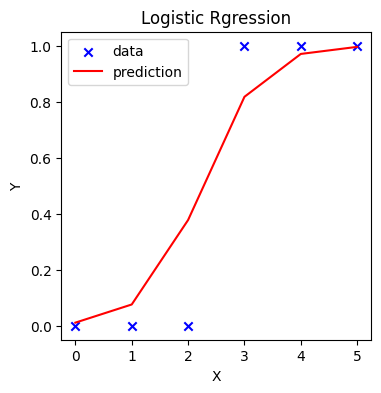

In [125]:
fig, ax = plt.subplots(1,1, figsize = (4,4))

ax.scatter(x, y, label="data", marker='x', c='b')
ax.plot(x, a1, label = "prediction", c='r')
ax.set_title("Logistic Rgression")
ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.legend()
plt.show()